# Take a result into another tool
Discover native export formats, download the region as GeoJSON and the field
as GeoTIFF, then open both files locally. These are actual service exports.
The numerical model is synthetic; the Runtime uses the branch-carried corrected
geospatial component, not the older published exporter.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from klab_client import connect, ObservationRequest, RectangularGeometry, open_raster
from notebook_setup import profile, certificate, track_session, reset_field

connection = connect(profile(), credentials=certificate())
client = connection.client
session = client.create_session(name="Notebook: native file exports")
track_session(session)
context = session.create_context()
region = context.observe(ObservationRequest("earth:Region",
    geometry=RectangularGeometry(200000, 200500, 6000000, 6000400, 5, 4))).result(120)
reset_field()
aspect = context.within(region).observe("geography:Aspect in degree_angle").result(120)

## Ask the Runtime what it can export
Choose from advertised formats instead of guessing a download URL.

In [2]:
formats = [{"observation": name, "format": f.media_type, "schema": f.schema_id}
           for name, observation in [("Region", region), ("Aspect", aspect)]
           for f in client.export_formats(observation)]
display(pd.DataFrame(formats))
assert any(row["format"] == "application/geo+json" for row in formats)
assert any(row["format"] == "image/tiff;application=geotiff" for row in formats)

,observation,format,schema
0,Region,application/geo+json,geospatial.io.geojson
1,Region,image/tiff;application=geotiff,geospatial.io.geotiff
2,Region,image/png,geospatial.io.png
3,Aspect,application/geo+json,geospatial.io.geojson
4,Aspect,image/tiff;application=geotiff,geospatial.io.geotiff
5,Aspect,image/png,geospatial.io.png


## Download GeoJSON and draw the exported boundary
The coordinates below come from the file, not the original request rectangle.

,longitude,latitude
0,1.796631,47.353705
1,1.796631,47.356139
2,1.801122,47.356139
3,1.801122,47.353705
4,1.796631,47.353705


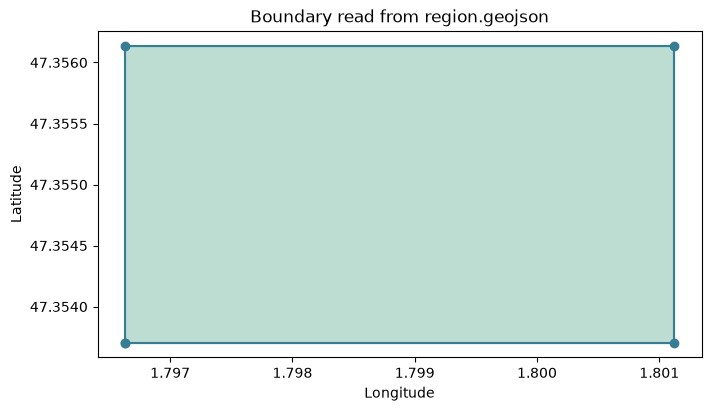

In [3]:
vector = region.export_to_file("region.geojson", media_type="application/geo+json")
payload = json.loads(vector.path.read_text())
feature = payload["features"][0]
ring = feature["geometry"]["coordinates"][0]
display(pd.DataFrame(ring, columns=["longitude", "latitude"]))
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
lon, lat = zip(*ring)
ax.fill(lon, lat, color="#70b49d", alpha=.45)
ax.plot(lon, lat, marker="o", color="#367d94")
ax.set(title="Boundary read from region.geojson", xlabel="Longitude", ylabel="Latitude")
ax.ticklabel_format(useOffset=False)
plt.show()
assert feature["id"] == region.id and ring[0] == ring[-1]

## Download the numerical GeoTIFF
Open it with the optional reader. The file supplies coordinates, units and
missingness; Python does not repair or rewrite the server's exported bytes.

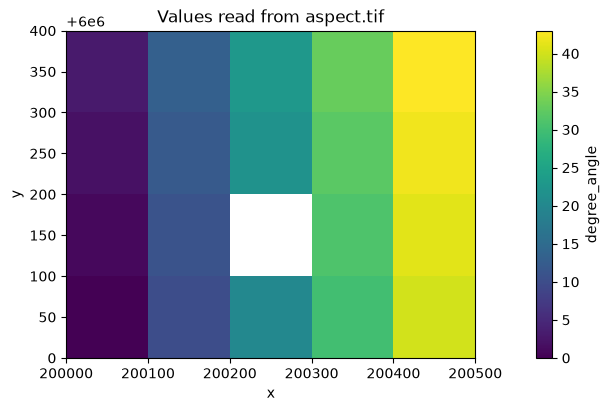

,file,bytes
0,region.geojson,806
1,aspect.tif,702


In [4]:
raster = aspect.export_to_file("aspect.tif", media_type="image/tiff;application=geotiff")
analysis = open_raster(raster.path)
ds = analysis.dataset
fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
ds.value.where(ds.valid).plot(ax=ax, cbar_kwargs={"label": analysis.descriptor.units})
ax.set(title="Values read from aspect.tif", aspect="equal")
plt.show()
display(pd.DataFrame([{"file": vector.path.name, "bytes": vector.bytes_written},
                      {"file": raster.path.name, "bytes": raster.bytes_written}]))
assert ds.value.dtype.name == "float64" and int(ds.valid.sum()) == 19
assert float(ds.value.where(ds.valid).sum()) == 409
assert ds.value.values[-1, 0] == 0 and bool(ds.valid.values[-1, 0])
assert float(ds.y.values[0]) == 6000350 and float(ds.x.values[0]) == 200050

## Existing files are not silently replaced
Overwriting is a deliberate choice. A failed or interrupted transfer must not
publish a partial replacement; that failure path is covered by the export tests.

In [5]:
from klab_client import ExportIOError

original = raster.path.read_bytes()
try:
    aspect.export_to_file("aspect.tif", media_type="image/tiff;application=geotiff")
except ExportIOError:
    print("The existing file was kept. Use overwrite=True to replace it deliberately.")
else:
    raise AssertionError("An existing file was overwritten without consent")
assert raster.path.read_bytes() == original
assert session.release()
connection.close()

The existing file was kept. Use overwrite=True to replace it deliberately.
